# Módulo 1: Fundamentos, espacios de color y mejoramiento digital

## 1.1 Carga, muestreo y espacios de color

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

from modulos import modulo0_importacion as m0
from modulos import modulo1_mejoramiento as m1

RUTA_VIDEO = "videos/registro_A1.MOV"
INDICE_FRAME = 0

### Frame representativo

Las dimensiones y la profundidad de bits son propiedades de la grabación y no dependen del frame elegido. Pero el submuestreo, la cuantización y el análisis de color sí dependen de lo que muestre la imagen, por lo que fijamos el frame de referencia tomando el frame 0, ya que nosotros vimos el video y corroboramos que en ese frame la imagen muestra lo que queremos ver, y el ojo se ve completo y nítido.

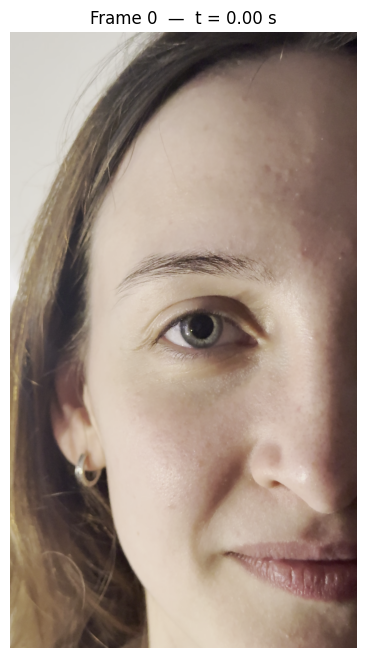

In [2]:
with m0.abrir_video(RUTA_VIDEO) as video:
    metadatos = m0.leer_metadatos(video, RUTA_VIDEO)
    frame = m0.leer_frame(video, INDICE_FRAME)

plt.figure(figsize=(6, 8))
plt.imshow(frame)
plt.title(f"Frame {INDICE_FRAME}  —  t = {INDICE_FRAME / metadatos['fps']:.2f} s")
plt.axis("off")
plt.show()

### Región de interés (ROI)

Por el mismo motivo que explicamos antes, elegimos definir la ROI a mano. Al ejecutar la celda se abre una ventana aparte con el frame seleccionado previamente, y el usuario tiene que arrastrar un rectángulo alrededor del ojo y confirmar con Enter ("c" cancela) para elegir la ROI, y las coordenadas quedan impresas. La ROI se marcó una vez a mano y quedó fija en la celda, así los resultados posteriores no cambian entre ejecuciones. Con ROI = None se vuelve a abrir la ventana.

ROI (x, y, ancho, alto) = (721, 1604, 922, 465)


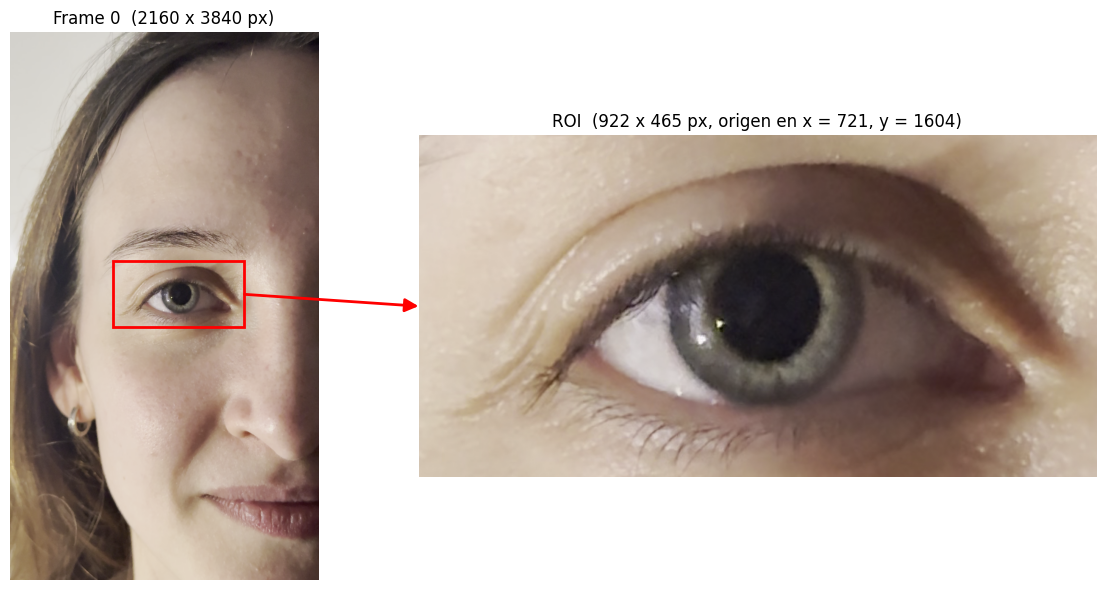

In [3]:
ROI = (721, 1604, 922, 465)  # (x, y, ancho, alto). Con None se abre la ventana de selección

if ROI is None:
    ROI = m0.seleccionar_roi(frame)
print("ROI (x, y, ancho, alto) =", ROI)

roi = m0.recortar_roi(frame, ROI)
m0.mostrar_roi(frame, ROI, INDICE_FRAME)

### Guardado del frame y la ROI

Se guardan en PNG (formato sin pérdida) en la carpeta del notebook, para que todo el análisis parta siempre de las mismas imágenes. Y como la librería cv2 trabaja con el orden BGR, se convierte el ROI de RGB a BGR antes de guardar.

In [4]:
cv2.imwrite(f"frame{INDICE_FRAME}.png", cv2.cvtColor(frame, cv2.COLOR_RGB2BGR))
cv2.imwrite(f"roi_frame{INDICE_FRAME}.png", cv2.cvtColor(roi, cv2.COLOR_RGB2BGR))
print(f"Guardados: frame{INDICE_FRAME}.png y roi_frame{INDICE_FRAME}.png")

Guardados: frame0.png y roi_frame0.png


### Carga de las imágenes para el análisis

Desde acá el análisis usa las imágenes guardadas. Después de reiniciar el notebook alcanza con ejecutar la primera celda y esta, sin abrir el video ni volver a seleccionar la ROI.

In [5]:
frame = cv2.imread(f"frame{INDICE_FRAME}.png")
roi = cv2.imread(f"roi_frame{INDICE_FRAME}.png")
if frame is None or roi is None:
    raise FileNotFoundError("No están las imágenes guardadas: ejecutar antes las celdas de frame, ROI y guardado")

frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
roi = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)

### Dimensiones y profundidad de bits

Se informan para el frame completo y para la ROI. El ancho y el alto salen de la forma de la matriz (`shape`), y la profundidad de bits, del tipo de dato (`uint8`: 8 bits por canal).

In [6]:
m1.imprimir_dimensiones(frame, f"Frame {INDICE_FRAME}")
m1.imprimir_dimensiones(roi, "ROI")

Frame 0
  Dimensiones (ancho x alto) : 2160 x 3840 px  (8.294.400 píxeles)
  Canales                    : 3
  Tipo de dato               : uint8
  Profundidad de bits        : 8 bits por canal (256 niveles), 24 bits por píxel
  Colores representables     : 16.777.216


  Colores distintos presentes: 152.605
  Rango de valores presente  : 0 a 255
  Memoria sin comprimir      : 24300,0 KB

ROI
  Dimensiones (ancho x alto) : 922 x 465 px  (428.730 píxeles)
  Canales                    : 3
  Tipo de dato               : uint8
  Profundidad de bits        : 8 bits por canal (256 niveles), 24 bits por píxel
  Colores representables     : 16.777.216
  Colores distintos presentes: 50.838
  Rango de valores presente  : 0 a 255
  Memoria sin comprimir      : 1256,0 KB



### Resolución espacial: submuestreo al 50 %, 25 % y 5 %

La ROI se reduce al 50 %, 25 % y 5 % de su resolución en cada eje; al 50 % por eje queda un cuarto de los píxeles. Se usa el vecino más cercano, conservando un píxel de cada 2, 4 y 20 por eje y se descartan los demás sin promediarlos. Es decir, no se aplica un filtro antialiasing, porque pensamos que es lo que el ejercicio nos pide justamente analizar.

Para comparar las versiones al mismo tamaño en pantalla, cada una se vuelve a ampliar a la resolución original repitiendo píxeles.

 50%:  461 x 232  px  ->  106.952 píxeles
 25%:  230 x 116  px  ->   26.680 píxeles
  5%:   46 x 23   px  ->    1.058 píxeles


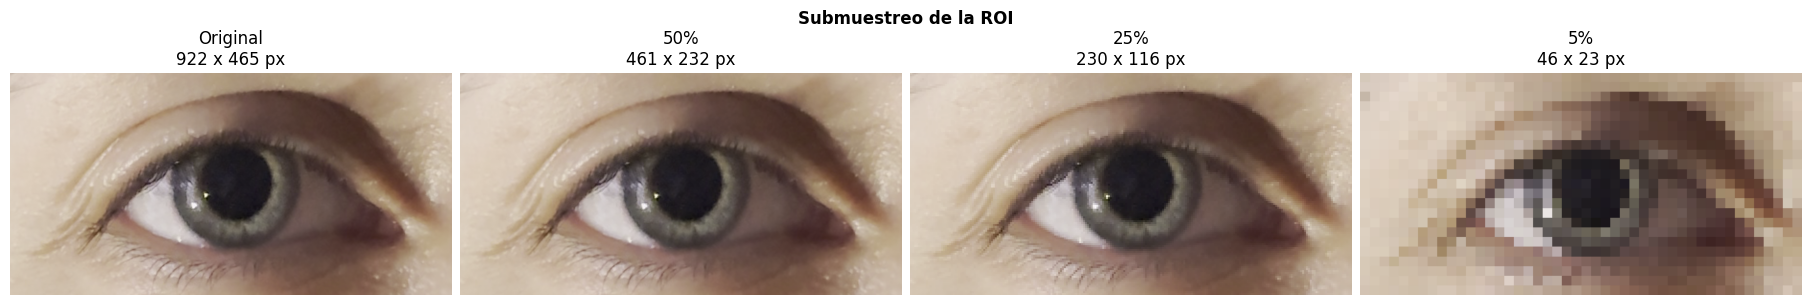

In [7]:
FACTORES = [0.50, 0.25, 0.05]

alto_roi, ancho_roi = roi.shape[:2]
imagenes = [roi]
titulos = [f"Original\n{ancho_roi} x {alto_roi} px"]

for factor in FACTORES:
    reducida = m1.submuestrear(roi, factor)
    alto_red, ancho_red = reducida.shape[:2]
    imagenes.append(m1.ampliar_a(reducida, alto_roi, ancho_roi))
    titulos.append(f"{factor:.0%}\n{ancho_red} x {alto_red} px")
    print(f"{factor:>4.0%}: {ancho_red:>4} x {alto_red:<4} px  ->  {m1.formato_miles(reducida.shape[0] * reducida.shape[1]):>7} píxeles")

m1.mostrar_fila(imagenes, titulos, "Submuestreo de la ROI")

Al reducir la resolución al 50 %, 25 % y 5 %, la ROI pasa de 428.730 píxeles a 106.952, 26.680 y 1.058 (que es 1/4, 1/16 y 1/400 de la original, respectivamente).

Al 50 % no se aprecian diferencias con la original. Al 25 % la pérdida empieza a percibirse en las estructuras finas, como las pestañas y los pliegues de la piel, que pierden nitidez. Pero los contornos de alto contraste, como entre pupila e iris, se mantienen definidos.

Al 5 % se pierden la textura de la piel, la circularidad de la pupila y del iris, y las pestañas quedan como una sucesión de bloques borrosos. Por como diseñamos el submuestreo (sin un filtro antialiasing) se observa que se toma un píxel de entre los vecinos sin promediar los descartados, haciendo que las estructuras de tamaño menor al paso de muestreo desaparezcan (aliasing espacial).

### Cuantización: de 8 bits a 4 y 2 bits

Cuantización uniforme: el rango 0–255 de cada canal se divide en 2<sup>b</sup> intervalos iguales (16 para 4 bits, 4 para 2 bits) y cada píxel toma el nivel de su intervalo. Los niveles se reparten en todo el rango 0–255 (con 2 bits: 0, 85, 170 y 255) para no alterar el brillo global.

Se aplica a la ROI en color, canal por canal, y a su versión en escala de grises, obtenida como la luminancia Y = 0,299 R + 0,587 G + 0,114 B.

8 bits: 256 niveles por canal | colores distintos en la ROI: 50.838 (máximo 16.777.216) | niveles de gris distintos: 243
4 bits:  16 niveles por canal | colores distintos en la ROI:    170 (máximo 4.096) | niveles de gris distintos:  16
2 bits:   4 niveles por canal | colores distintos en la ROI:     16 (máximo 64) | niveles de gris distintos:   4


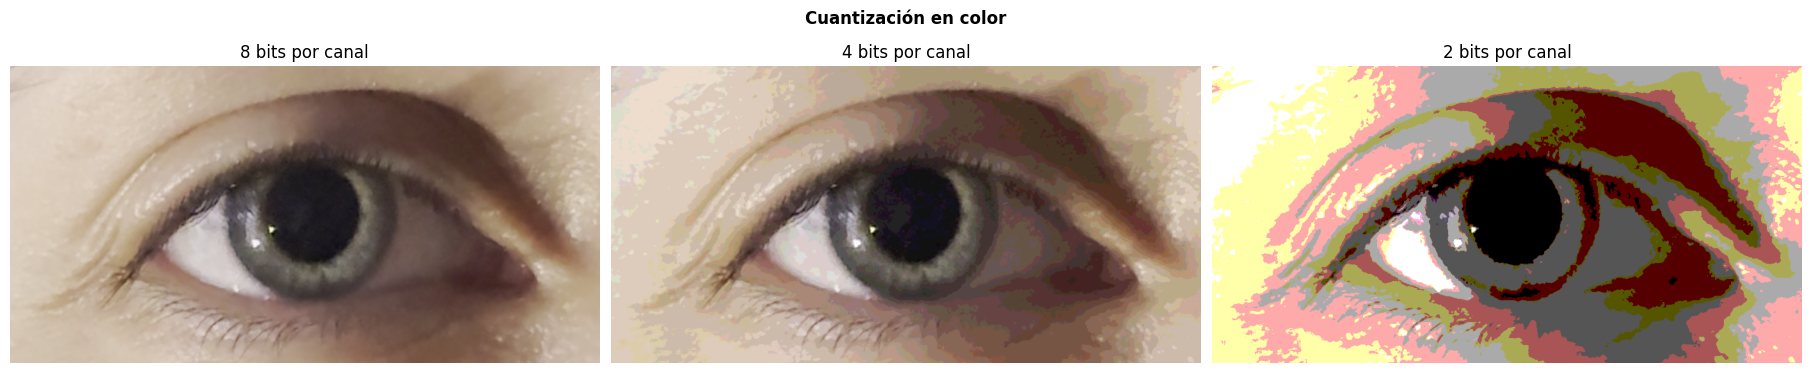

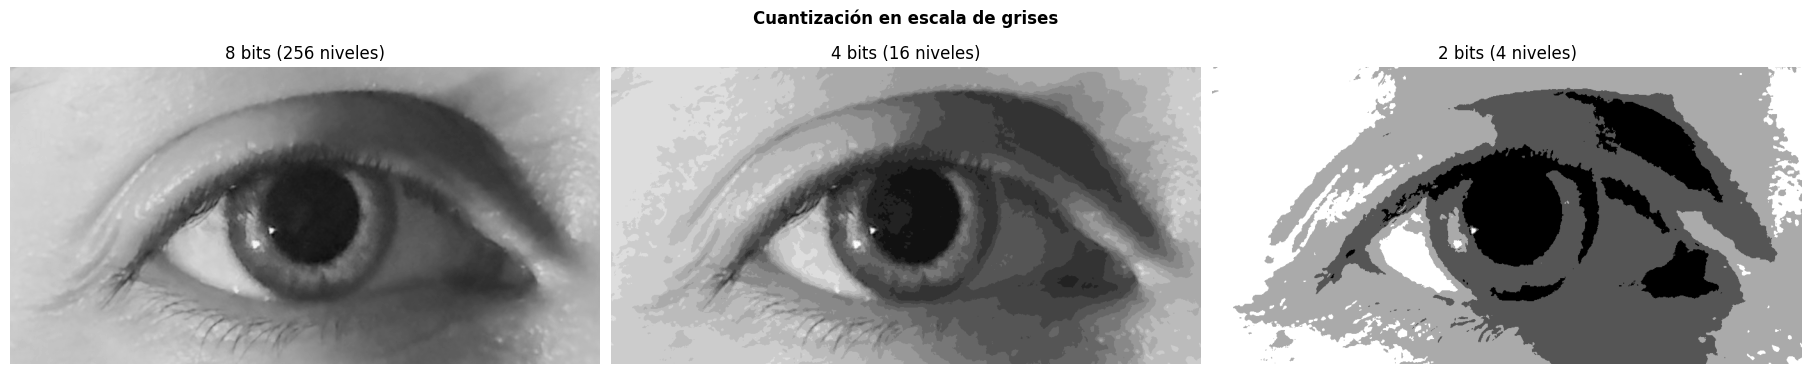

In [8]:
BITS = [8, 4, 2]

gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)
color_cuantizada = [m1.cuantizar(roi, b) for b in BITS]
gris_cuantizada = [m1.cuantizar(gris, b) for b in BITS]

for b, c, g in zip(BITS, color_cuantizada, gris_cuantizada):
    print(f"{b} bits: {2 ** b:>3} niveles por canal | "
          f"colores distintos en la ROI: {m1.formato_miles(m1.contar_colores(c)):>6} (máximo {m1.formato_miles(2 ** (3 * b))}) | "
          f"niveles de gris distintos: {m1.contar_colores(g):>3}")

m1.mostrar_fila(color_cuantizada, [f"{b} bits por canal" for b in BITS], "Cuantización en color")
m1.mostrar_fila(gris_cuantizada, [f"{b} bits ({2 ** b} niveles)" for b in BITS], "Cuantización en escala de grises")

Con 4 bits por canal, la imagen en color conserva su aspecto general y todas las estructuras del ojo. Sin embargo, en las regiones de variación suave (como la región por arriba del párpado, o la región debajo de las pestañas inferiores) aparece un falso contorneo, con colores separados por bordes abruptos y notorios.

Con 2 bits por canal, la degradación es mayor. Como cada canal se cuantiza por separado, R, G y B cruzan los umbrales en posiciones distintas, y aparecen tintes que no estaban en la imagen original, que se ven como manchas rojizas, amarillentas y verdosas en la piel. Por otro lado, las zonas más oscuras de la piel pasan a gris. La pupila, salvo los reflejos blancos, cae en el nivel 0 de los tres canales, y el iris cae en gris, por lo que el contorno pupila-iris se preserva. Sin embargo, el borde superior de la pupila se fusiona en tonalidad con el borde superior del párpado, por lo que esto podría afectar la segmentación en pasos posteriores.

En la escala de grises el falso contorneo es más evidente que a color. Se observa que los degradés de la piel y de la sombra del párpado se transforman en bandas de igual luminancia, mientras que la pupila, el iris, la esclerótica y las pestañas preservan una mejor definición.

### Espacios de color: canales RGB y conversión a HSV

Cada canal R, G y B se muestra como una imagen en escala de grises, y cuanto más claro el píxel, mayor la intensidad de ese color.

En HSV, H (matiz) se muestra en grados con un mapa de colores cíclico; S (saturación) y V (valor) se muestran en grises.

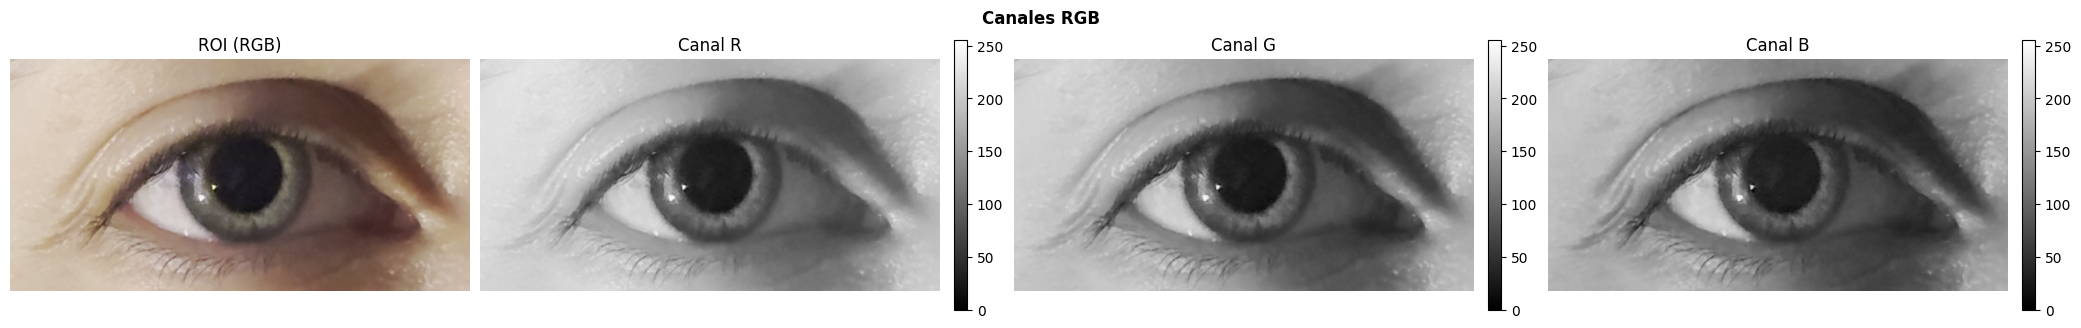

In [9]:
R, G, B = roi[..., 0], roi[..., 1], roi[..., 2]
m1.mostrar_fila([roi, R, G, B], ["ROI (RGB)", "Canal R", "Canal G", "Canal B"],
                "Canales RGB", barra_color=True)

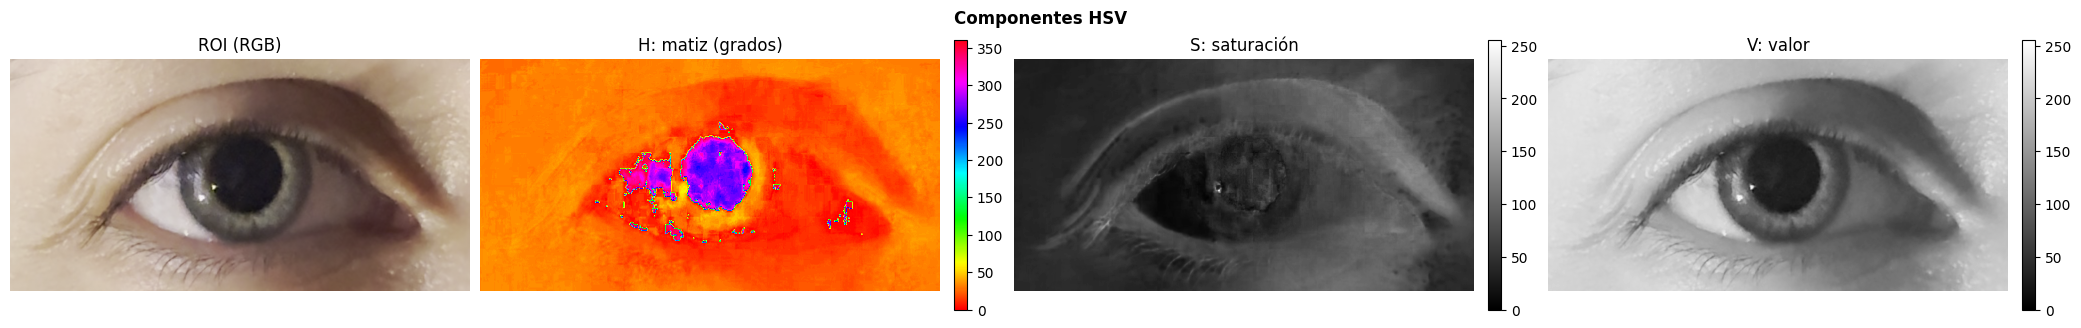

In [10]:
H, S, V = m1.rgb_a_hsv(roi)
m1.mostrar_fila([roi, H, S, V], ["ROI (RGB)", "H: matiz (grados)", "S: saturación", "V: valor"],
                "Componentes HSV", cmap=[None, "hsv", "gray", "gray"],
                rango=[None, (0, 360), (0, 255), (0, 255)], barra_color=True)

En los canales RGB, la piel aparece clara en R y más oscura en G y en B. Una posible explicación para esto es que la hemoglobina y la melanina absorben con mayor intensidad en el verde y en el azul, así que en el rojo hay poca absorción, y por lo tanto se ve más claro. Por este mismo motivo, en R la piel se ve más uniforme y las sombras del pliegue del párpado y de la ojera quedan más atenuadas, mientras que en G y en B se marcan con claridad. Por otro lado, como la esclerótica tiene valores similares en los tres canales, en R se confunde con la piel que la rodea y en B destaca como una de las regiones más claras.

La pupila es oscura en los tres canales, y el contraste entre pupila e iris es similar en todos. Para la segmentación, R podría llegar a ser más útil ya que tiene un buen contraste pupila-iris y además tiene una alta atenuación de las sombras de la piel, que en escala de grises compiten con la pupila por los niveles más bajos.

En HSV, V (valor) se define como el máximo de R, G y B. Como en la piel predomina el rojo, V resulta muy parecida al canal R.

H (matiz) es considerablemente uniforme en la piel, con tonos de naranja, y un naranja más oscuro en el párpado. En la pupila toma valores de azul/violeta. En el iris, sobre todo en su sector izquierdo y alrededor de los reflejos, varía entre magenta, violeta, verde y amarillo. Esto último ocurre porque el matiz se calcula a partir de la diferencia entre el máximo y el mínimo de los tres canales; cuando esa diferencia es de pocas unidades, como en la pupila y en el iris poco saturado, con tan sólo el ruido del sensor y de la compresión alcanza para desplazar el valor de H a cualquier punto del círculo cromático.

S (saturación) es baja en casi toda la ROI y mínima en la esclerótica, que es casi blanca, y en casi todo el perímetro de la ROI. Las zonas más saturadas son el pliegue y la ojera. La pupila aparece más saturada que el iris y que la piel.

En conclusión, como H y S son muy inestables en la pupila y el iris, no aportarían información adicional al análisis de la ROI. La pupila se distingue por su baja intensidad, y su segmentación debería apoyarse en el canal V, en la escala de grises o en un canal individual como R.